# coevolution-substrate (#3 / #3c) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**Does egene co-evolution amplify rule selection — and is there a real penalty for *freezing*
the substrate rule?** (#3 asked whether egene evolution depends on the substrate; #3c is the
clean decisive test.)

## Method

`3c_coevolution_substrate` (`Docs/plan-3c-coevolution-substrate.md`): evolve LUT-only for a
phase-1 settle (3000 ticks), then **in situ** switch to egene-only evolution for phase 2 (8000
ticks). Four arms, 80 runs, determinism-checked (30/30 A/C pairs `determinism_ok=True`, shared
fork valid):

- **A** — freeze the *evolved* LUT (`mu_lut=0`), evolve egene;
- **C** — keep the LUT **co-evolving**, evolve egene (byte-identical substrate to A at switch);
- **B** — freeze **GoL** (not the evolved rule) — anchor;
- **B′** — viable frozen-GoL anchor.

Substrate premise confirmed: A/C `frac_evolved = 1.000`, ~38k distinct LUTs at the switch.

## Headline result (honest / mixed)

The #3 "3a ≫ 3b" gap is **mostly a GoL-substrate viability collapse, not a clean co-evolution
synergy**: plain frozen-GoL (**B**) goes **10/10 extinct**; viable frozen-GoL (**B′**) shows
**flat-zero egene excess**. Holding the substrate byte-identical, co-evolving the rule (**C**)
beats freezing it (**A**) only **modestly but consistently** (paired C−A `eg_excess_pc > 0` in
22/30, mean +0.6); the absolute egene signal is **weak** (|slopes| ≲ 1 vs #1's 20–135) and has
**plateaued by ticks 7–8k**. **Methodological load-bearing caveat:** arm A's
`dyn_excess_pc_slope ≈ +335` is the **frozen-rich-substrate artifact**, not biology (see the
`neutral-model-methodology` draft, Bug 2).

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_restructure


In [2]:
c3 = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-05-19_3c_coevolution_substrate/results.csv")
byarm = c3.groupby("arm").agg(
    n=("arm", "size"),
    extinct=("extinct", "sum"),
    eg_excess_pc_slope=("eg_excess_pc_slope", "mean"),
    dyn_excess_pc_slope=("dyn_excess_pc_slope", "mean"),
    frac_evolved=("sub_frac_evolved", "mean"),
).round(3).reindex(["A", "C", "B", "B'"])
display(byarm)


,n,extinct,eg_excess_pc_slope,dyn_excess_pc_slope,frac_evolved
arm,,,,,
A,30,0,-0.380,335.327,1.0
C,30,0,0.236,1.005,1.0
B,10,10,0.000,0.000,0.0
B',10,0,-0.000,0.000,0.0


### GoL-substrate death confound (B) and the paired C vs A comparison

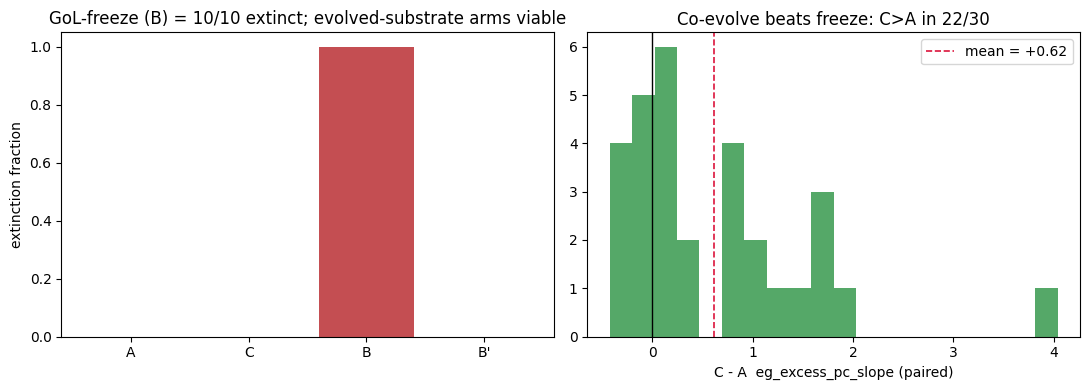

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) extinction by arm
order = ["A", "C", "B", "B'"]
ext = [c3.query("arm==@a").extinct.mean() for a in order]
axes[0].bar(order, ext, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
axes[0].set_ylabel("extinction fraction")
axes[0].set_title("GoL-freeze (B) = 10/10 extinct; evolved-substrate arms viable")

# (b) paired C - A eg excess (matched config_idx/seed)
key = ["config_idx", "seed"] if "seed" in c3.columns else ["config_idx"]
a = c3.query("arm=='A'").set_index(key).eg_excess_pc_slope
cc = c3.query("arm=='C'").set_index(key).eg_excess_pc_slope
paired = (cc - a).dropna()
axes[1].hist(paired, bins=20, color="#55A868")
axes[1].axvline(0, color="k", lw=1)
axes[1].axvline(paired.mean(), color="crimson", lw=1.2, ls="--",
                label=f"mean = {paired.mean():+.2f}")
axes[1].set_xlabel("C - A  eg_excess_pc_slope (paired)")
axes[1].set_title(f"Co-evolve beats freeze: C>A in {int((paired>0).sum())}/{len(paired)}")
axes[1].legend()
fig.tight_layout(); plt.show()


### The `dyn_excess_pc` artifact on the frozen rich substrate

Arm A (`mu_lut=0` on the *evolved* substrate) shows a huge `dyn_excess_pc_slope` — **do not
read this as selection.** It is the frozen-rich-substrate baseline collapse (Bug 2 in the
`neutral-model-methodology` draft). Arm C (LUT co-evolving) is well-posed and small.

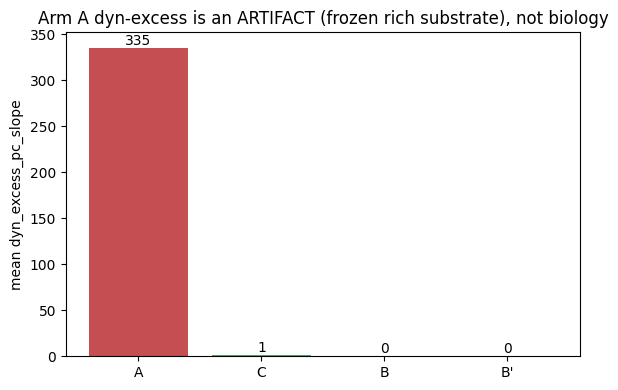

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["A", "C", "B", "B'"]
vals = [c3.query("arm==@a").dyn_excess_pc_slope.mean() for a in order]
bars = ax.bar(order, vals, color=["#C44E52", "#55A868", "#999999", "#999999"])
ax.set_ylabel("mean dyn_excess_pc_slope")
ax.set_title("Arm A dyn-excess is an ARTIFACT (frozen rich substrate), not biology")
ax.bar_label(bars, fmt="%.0f")
fig.tight_layout(); plt.show()


*Sources:* `Scans/2026-05-19_3c_coevolution_substrate/`,
`Docs/plan-3c-coevolution-substrate.md`, `Docs/devlog/2026-05-17_research-campaigns.md` (#3c
section), project memory `dyn-shadow-frozen-rich-substrate`.